# 05 - Results Visualizations
Loads the models saved by notebook 04 and the Test split from notebook 02, then renders a few ways of looking at what the model actually predicts — most importantly, the buy/sell signal painted directly on the price chart.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.metrics import pearson_ic, spearman_ic, hit_rate
from src.visualization import plot_price_with_signal, plot_holding_windows, rolling_ic

DATA_DIR = PROJECT_ROOT / 'data'
MODEL_DIR = DATA_DIR / 'models'
SPLIT_DIR = DATA_DIR / 'splits'

In [2]:
test = pd.read_parquet(SPLIT_DIR / 'test.parquet')
target_col = [c for c in test.columns if c.startswith('fwd_log_return')][0]
feature_cols = [c for c in test.columns if c != target_col]
HORIZON = int(target_col.rsplit('_', 1)[1])  # bars held per trade, baked into the target
X_test, y_test = test[feature_cols], test[target_col]

raw_close = pd.read_parquet(DATA_DIR / 'raw_close.parquet')['close']
price_test = raw_close.loc[test.index]

results = pd.read_parquet(MODEL_DIR / 'results.parquet')
results

,pearson_ic,spearman_ic,hit_rate
model,,,
Ridge(alpha=1.0),0.041645,-0.040118,0.471380
XGBoost(loss=huber),0.060334,0.106790,0.544332


## Pick a model to visualize
Defaults to whichever saved model has the best out-of-sample Spearman IC.

In [3]:
available_models = {p.stem: joblib.load(p) for p in MODEL_DIR.glob('*.joblib')}
print('Available:', list(available_models.keys()))

MODEL_KEY = results['spearman_ic'].idxmax()
# results is indexed by model.name (e.g. 'XGBoost(loss=huber)'), map back to the saved key
MODEL_KEY = next(k for k, m in available_models.items() if m.name == MODEL_KEY)
model = available_models[MODEL_KEY]
print('Visualizing:', model.name)

pred = model.predict(X_test)

Available: ['ridge', 'xgboost']
Visualizing: XGBoost(loss=huber)


## 1. Buy/sell signal + holding window on the price chart
Green = buy signal (predicted forward return positive), red = sell signal (negative). Color intensity = percentile strength of that prediction relative to the rest of the test set.

The shaded spans + double arrows mark the model's strongest entries: each spans exactly `HORIZON` bars (the forecast horizon baked into the target) — **that's the holding period**, since this model doesn't decide exit timing dynamically, it always holds for `k` bars then re-evaluates.

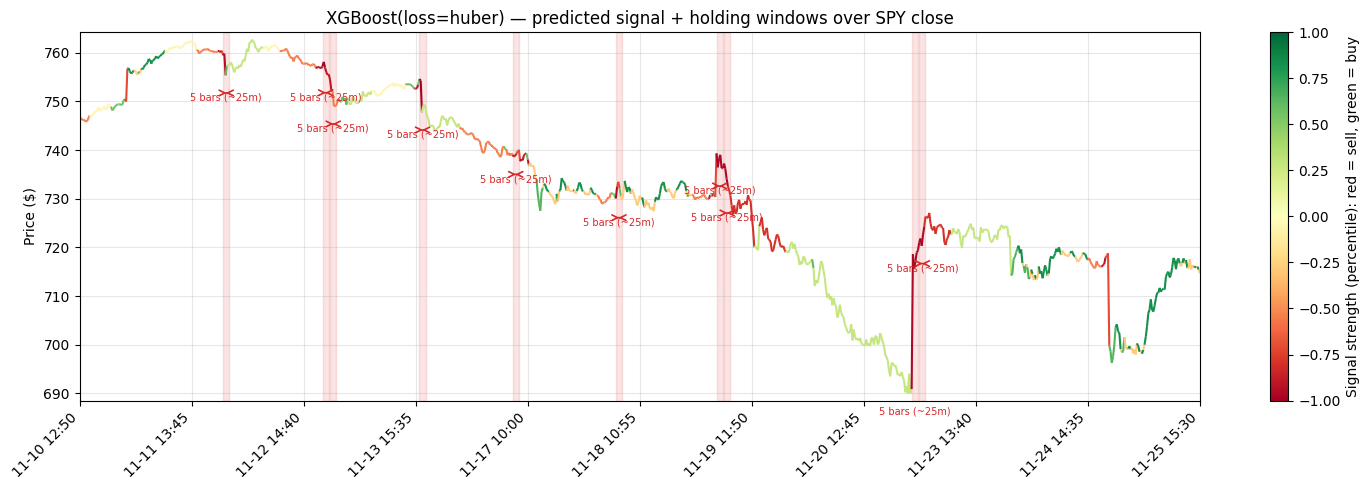

Showing 10 non-overlapping example trades, each held for 5 bars.


In [4]:
fig, ax = plt.subplots(figsize=(15, 5))
plot_price_with_signal(price_test.index, price_test, pred,
                        title=f'{model.name} — predicted signal + holding windows over SPY close', ax=ax)
selected_entries = plot_holding_windows(ax, price_test, pred, horizon=HORIZON,
                                         index=price_test.index, max_windows=10,
                                         strength_threshold=0.85)
plt.tight_layout()
plt.show()
print(f'Showing {len(selected_entries)} non-overlapping example trades, each held for {HORIZON} bars.')

## 2. Predicted vs. actual return
Colored by whether the sign was predicted correctly.

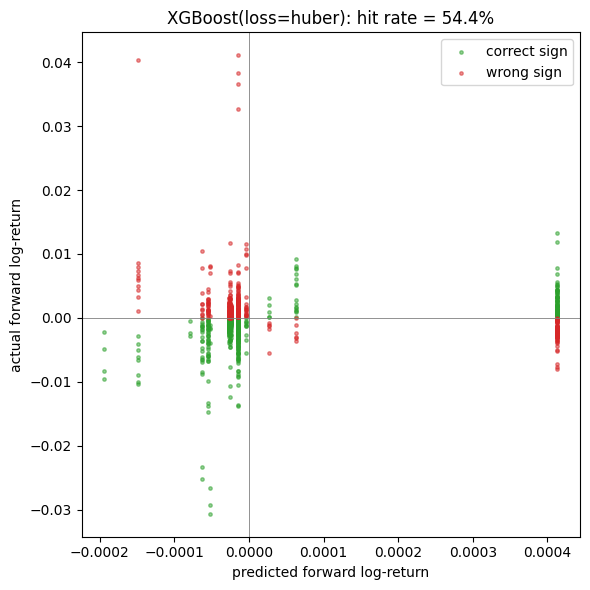

In [5]:
correct = np.sign(pred) == np.sign(y_test.to_numpy())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pred[correct], y_test.to_numpy()[correct], s=6, alpha=0.5, color='#2ca02c', label='correct sign')
ax.scatter(pred[~correct], y_test.to_numpy()[~correct], s=6, alpha=0.5, color='#d62728', label='wrong sign')
ax.axhline(0, color='gray', linewidth=0.6)
ax.axvline(0, color='gray', linewidth=0.6)
ax.set_xlabel('predicted forward log-return')
ax.set_ylabel('actual forward log-return')
ax.set_title(f'{model.name}: hit rate = {hit_rate(y_test.to_numpy(), pred):.1%}')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Rolling Information Coefficient
Is predictive skill stable over the test period, or concentrated in a few regimes?

/Users/user/Desktop/python/quant/CNN-agent/src/visualization.py:134: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(sub_true, sub_pred)[0]


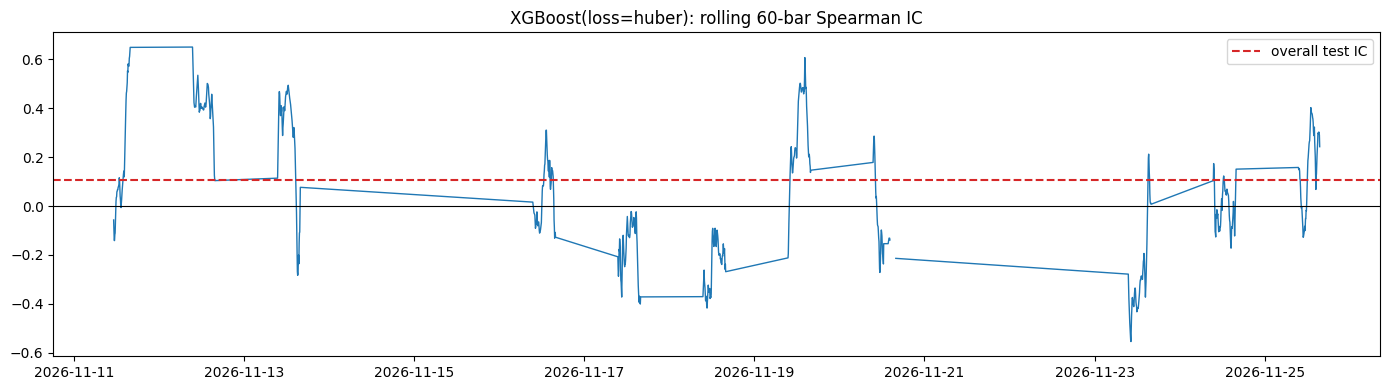

In [6]:
ROLLING_WINDOW = 60  # bars

ric = rolling_ic(y_test, pred, window=ROLLING_WINDOW, method='spearman')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ric.index, ric.values, color='#1f77b4', linewidth=1)
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(spearman_ic(y_test.to_numpy(), pred), color='#d62728', linestyle='--',
           label='overall test IC')
ax.set_title(f'{model.name}: rolling {ROLLING_WINDOW}-bar Spearman IC')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Compare all saved models on the signal chart

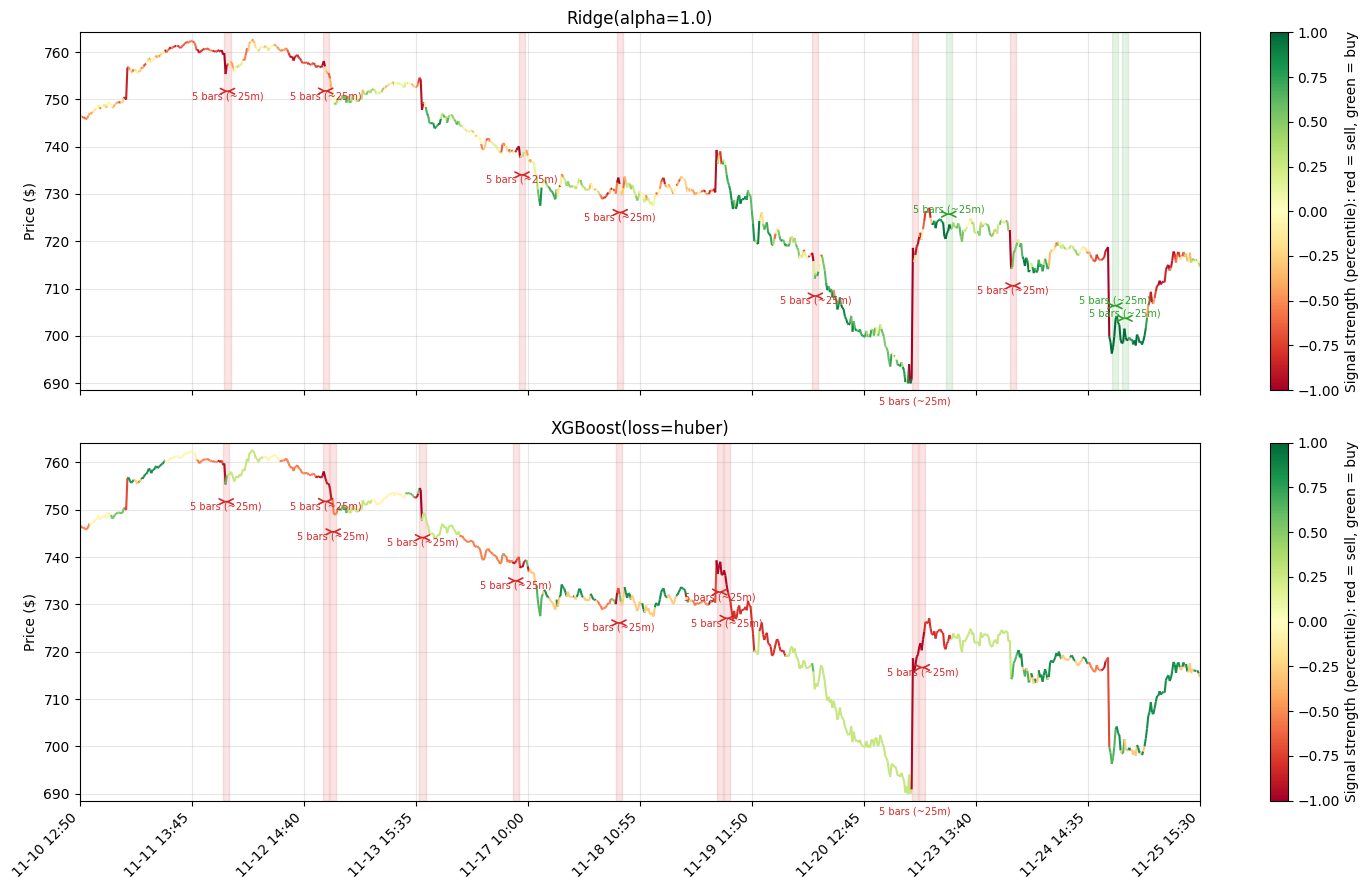

In [7]:
fig, axes = plt.subplots(len(available_models), 1, figsize=(15, 4.5 * len(available_models)), sharex=True)
if len(available_models) == 1:
    axes = [axes]
for ax, (key, m) in zip(axes, available_models.items()):
    m_pred = m.predict(X_test)
    plot_price_with_signal(price_test.index, price_test, m_pred, title=m.name, ax=ax)
    plot_holding_windows(ax, price_test, m_pred, horizon=HORIZON, index=price_test.index,
                          max_windows=10, strength_threshold=0.85)
plt.tight_layout()
plt.show()